# Diabetes Prediction using Machine Learning
End-to-end classification pipeline using Pandas and Scikit-learn.

### Assignment coverage
| Part | Task | Where |
|---|---|---|
| 1 | Load the dataset with Pandas | Part 1 · step 1 |
| 1 | Shape, column names, data types, missing values, statistical summary | Part 1 · step 2 |
| 1 | Separate features (X) and target (y) | Part 1 · step 3 |
| 1 | Train-test split | Part 1 · step 4 |
| 1 | Handle missing values, encode categoricals, scale features | Part 1 · step 5 |
| 1 | Feature engineering and feature selection | Part 1 · step 6 |
| 2 | Import libraries; implement and train Logistic Regression; explain the choice | Part 2 · steps 1–4 |
| 3 | Fit, predict on training data, training accuracy | Part 3 · steps 1–3 |
| 3 | Test accuracy, precision, recall, F1, confusion matrix, train vs. test comparison, interpretation | Part 3 · test evaluation |
| 4 | Overall performance analysis and conclusions | Part 4 |

## Part 1 — Data Preparation
### 1. Load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 2. Explore the dataset

In [2]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values (NaN):")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (768, 9)

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zero counts in columns where zero is physiologically impossible:")
print((df[cols] == 0).sum())
print("\nClass distribution:")
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))

Zero counts in columns where zero is physiologically impossible:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


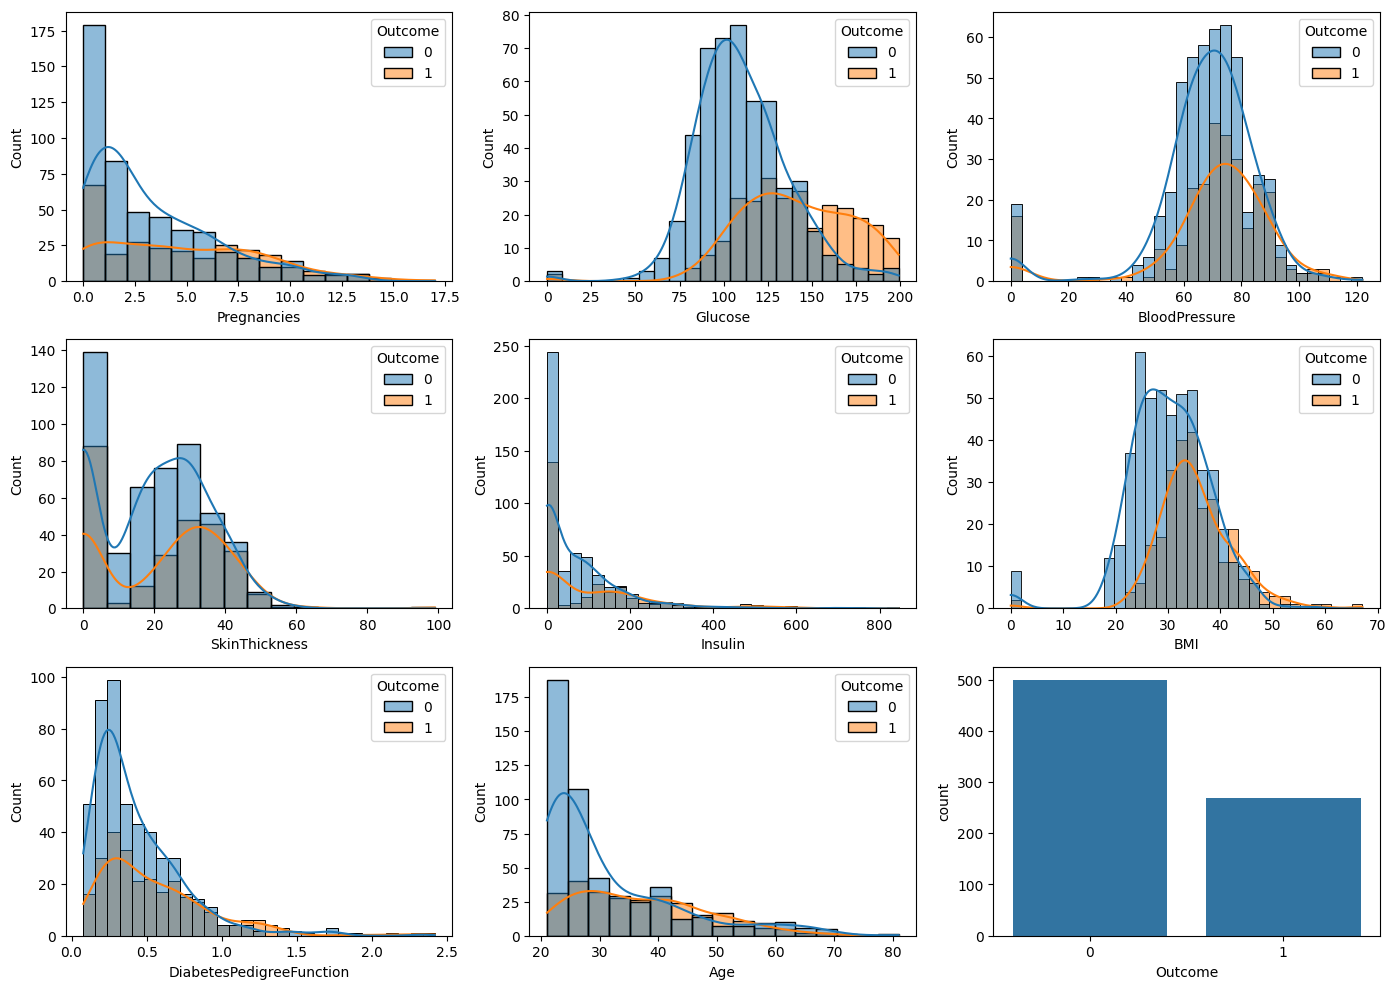

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax)
sns.countplot(data=df, x="Outcome", ax=axes[2, 2])
plt.tight_layout()
plt.show()

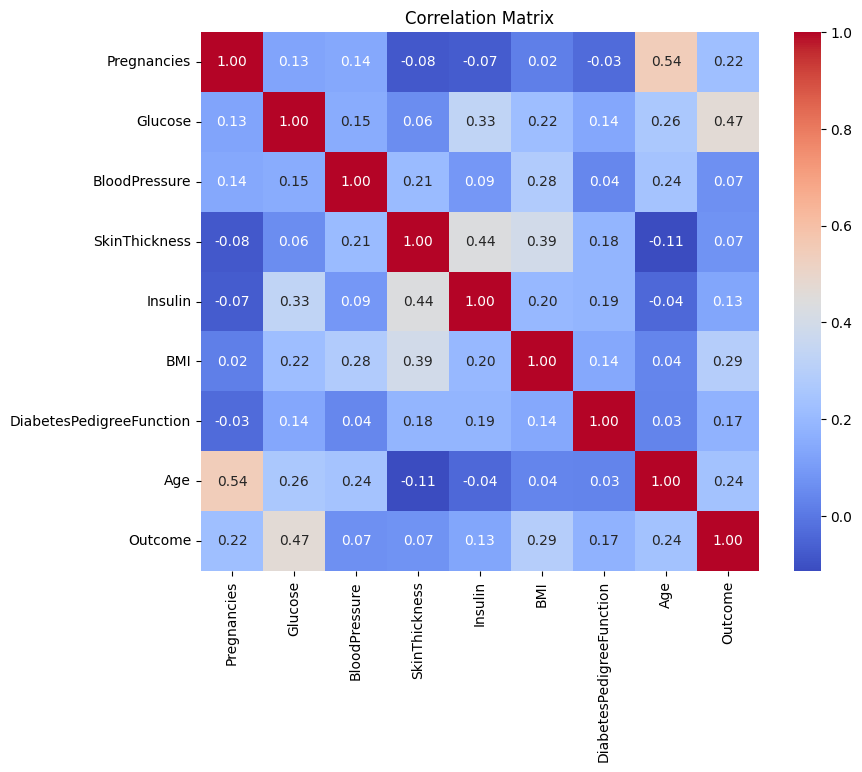

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

**Exploration summary**
- 768 rows, 9 columns; all columns are numeric (no categorical variables).
- No `NaN` values, but `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` contain zeros, which are physiologically impossible and represent hidden missing values. `SkinThickness` and `Insulin` are the worst affected.
- The target is imbalanced: about 65% non-diabetic and 35% diabetic.
- `Glucose` has the strongest correlation with `Outcome`, followed by `BMI`, `Age` and `Pregnancies`.

### 3. Features and target
| Column | Role | Description |
|---|---|---|
| Pregnancies | Feature | Number of times pregnant |
| Glucose | Feature | Plasma glucose concentration |
| BloodPressure | Feature | Diastolic blood pressure |
| SkinThickness | Feature | Triceps skin fold thickness |
| Insulin | Feature | Serum insulin level |
| BMI | Feature | Body Mass Index |
| DiabetesPedigreeFunction | Feature | Diabetes pedigree score |
| Age | Feature | Age of the patient |
| Outcome | **Target** | 0 = No Diabetes, 1 = Diabetes |

In [7]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
print(X.shape, y.shape)

(768, 8) (768,)


### 4. Train-test split
An 80/20 stratified split keeps the class ratio the same in both sets. The split happens before any preprocessing is fitted, which prevents data leakage.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

Training set: (614, 8) | Testing set: (154, 8)
Train class ratio: 0.349 | Test class ratio: 0.351


### 5. Preprocessing
- **Missing values:** zeros in the five columns above are converted to `NaN` and imputed with the median of the training set (median is robust to the skew in `Insulin` and `SkinThickness`).
- **Categorical encoding:** not required, as all features are numeric.
- **Scaling:** features are standardised (zero mean, unit variance) using statistics from the training set only, because Logistic Regression is sensitive to feature scale.

In [9]:
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols] = X_train[cols].replace(0, np.nan)
X_test[cols] = X_test[cols].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

print("Missing values after imputation (train):", np.isnan(X_train_imp).sum())
print("Scaled train mean (approx):", X_train_s.mean(axis=0).round(2))
print("Scaled train std:", X_train_s.std(axis=0).round(2))
print("\nTraining size:", X_train_s.shape[0], "| Testing size:", X_test_s.shape[0])

Missing values after imputation (train): 0
Scaled train mean (approx): [-0. -0.  0. -0. -0.  0. -0. -0.]
Scaled train std: [1. 1. 1. 1. 1. 1. 1. 1.]

Training size: 614 | Testing size: 154


### 6. Feature engineering and feature selection
Two ideas are tested before the final model is chosen:
- **Feature engineering:** missing-value flags for `Insulin` and `SkinThickness` (whether a reading was taken may itself carry information), plus two interaction terms, `Glucose × BMI` and `Age × Pregnancies`.
- **Feature selection:** keep only the top *k* features ranked by an ANOVA F-test (`SelectKBest`).

Each option is wrapped in a `Pipeline` and scored with 5-fold stratified cross-validation on the **training set only**, so imputation, scaling and selection are re-fitted inside every fold and the test set stays untouched.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_validate

def mark_missing(X):
    X = X.copy()
    X[cols] = X[cols].replace(0, np.nan)
    return X

def engineer(X):
    X = mark_missing(X)
    X["Insulin_missing"] = X["Insulin"].isna().astype(int)
    X["SkinThickness_missing"] = X["SkinThickness"].isna().astype(int)
    X["Glucose_x_BMI"] = X["Glucose"] * X["BMI"]
    X["Age_x_Pregnancies"] = X["Age"] * X["Pregnancies"]
    return X

def build(transform, k=None):
    steps = [FunctionTransformer(transform), SimpleImputer(strategy="median"), StandardScaler()]
    if k:
        steps.append(SelectKBest(f_classif, k=k))
    return make_pipeline(*steps, LogisticRegression(max_iter=1000, random_state=42))

candidates = {
    "All 8 original features": build(mark_missing),
    "Original + 4 engineered features": build(engineer),
    "Top 6 selected features": build(mark_missing, k=6),
    "Top 5 selected features": build(mark_missing, k=5),
    "Top 4 selected features": build(mark_missing, k=4),
}

X_train_raw, _, _, _ = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, pipe in candidates.items():
    scores = cross_validate(pipe, X_train_raw, y_train, cv=cv, scoring=["accuracy", "f1"])
    rows[name] = {"CV accuracy": scores["test_accuracy"].mean(),
                  "CV accuracy std": scores["test_accuracy"].std(),
                  "CV F1": scores["test_f1"].mean()}
cv_results = pd.DataFrame(rows).T.round(4)
cv_results

,CV accuracy,CV accuracy std,CV F1
All 8 original features,0.7882,0.0191,0.6545
Original + 4 engineered features,0.7899,0.0194,0.6598
Top 6 selected features,0.7817,0.0238,0.6495
Top 5 selected features,0.7752,0.0249,0.6410
Top 4 selected features,0.7752,0.0284,0.6356


In [11]:
selector = SelectKBest(f_classif, k="all").fit(X_train_s, y_train)
pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False).round(2).rename("ANOVA F-score")

Glucose                     217.76
BMI                          74.17
Insulin                      39.39
Age                          37.63
SkinThickness                35.54
Pregnancies                  27.72
BloodPressure                21.29
DiabetesPedigreeFunction     17.19
Name: ANOVA F-score, dtype: float64

**Feature engineering and selection result**
- The engineered features raise cross-validated accuracy by only about 0.2 points (78.8% → 79.0%), far smaller than the fold-to-fold standard deviation (about 1.9 points), so the gain is noise rather than real improvement.
- Keeping only the top 4–6 features makes cross-validated accuracy and F1 slightly worse, so every original feature contributes some signal.
- The ANOVA F-scores rank `Glucose` as by far the strongest feature, followed by `BMI`. `Insulin` ranks third here once its zeros are imputed, but it adds little in the model because its information overlaps with `Glucose` (its coefficient is close to zero in Part 3).

**Decision:** the final model uses all 8 original features with median imputation and standardisation. This is the simplest option and performs as well as the more complex ones.

**Part 1 deliverables:** exploration summary above; features and target described in the table; preprocessing is median imputation of hidden missing values plus standardisation; feature engineering and selection were evaluated with cross-validation and the 8 original features were kept; the split is **614 training / 154 testing** samples.

## Part 2 — Machine Learning Model Building
### 1. Import the required libraries

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

### 2. Select and implement the classification algorithm
The selected algorithm is **Logistic Regression**.

In [13]:
model = LogisticRegression(max_iter=1000, random_state=42)
model

LogisticRegression(max_iter=1000, random_state=42)

### 3. Train the model
The model is trained on the prepared training set (614 samples, imputed and standardised). Fitting, training predictions and training accuracy are shown step by step in Part 3 below.

### 4. Why Logistic Regression suits this problem
- The task is binary classification (diabetes vs. no diabetes) and Logistic Regression models the probability of the positive class directly.
- The dataset is small (768 rows) with eight numeric features, so a simple model is less likely to overfit than complex ones.
- Coefficients are interpretable, which matters in a medical setting: each one shows how a feature changes the odds of diabetes.
- It is fast to train and gives probabilities, so the decision threshold can be tuned.
- It also makes a strong baseline against which other models can be compared.

**Part 2 deliverables:** model implemented is `LogisticRegression(max_iter=1000)` from Scikit-learn; the reasons for choosing it are listed above.

## Part 3 — Model Training
### 1. Fit the model on the training dataset

In [14]:
model.fit(X_train_s, y_train)
print("Model trained.")
print("Iterations to converge:", model.n_iter_)
print("Intercept:", model.intercept_.round(3))
coef = pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False)
print("\nCoefficients:")
print(coef.round(3))

Model trained.
Iterations to converge: [8]
Intercept: [-0.872]

Coefficients:
Glucose                     1.183
BMI                         0.689
Pregnancies                 0.377
DiabetesPedigreeFunction    0.233
Age                         0.148
SkinThickness               0.028
BloodPressure              -0.044
Insulin                    -0.066
dtype: float64


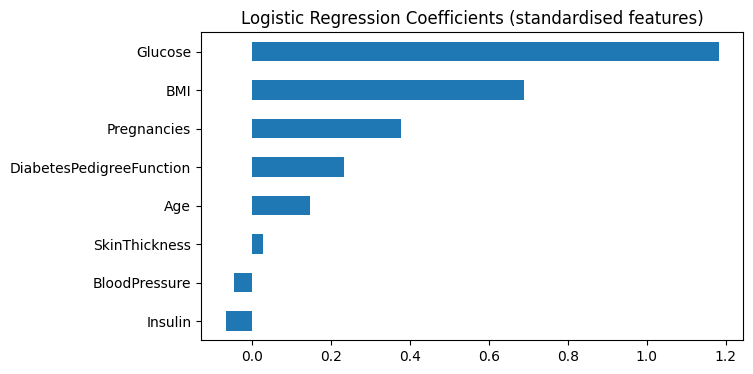

In [15]:
coef.sort_values().plot(kind="barh", figsize=(7, 4), title="Logistic Regression Coefficients (standardised features)")
plt.show()

### 2. Generate predictions on the training dataset

In [16]:
y_train_pred = model.predict(X_train_s)
print("Predictions on the first 10 training samples:", y_train_pred[:10])
print("Actual labels for the same samples:          ", y_train.values[:10])

Predictions on the first 10 training samples: [0 0 0 0 0 1 0 1 0 0]
Actual labels for the same samples:           [0 0 0 0 0 1 1 1 0 0]


### 3. Evaluate performance: training accuracy

In [17]:
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7964


### Evaluate on the test set
Predictions are generated on the unseen test set to measure accuracy, precision, recall, F1-score and the confusion matrix.

In [18]:
y_test_pred = model.predict(X_test_s)
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"Test accuracy : {test_acc:.4f}")
print(f"Precision     : {test_prec:.4f}")
print(f"Recall        : {test_rec:.4f}")
print(f"F1-score      : {test_f1:.4f}")
print()
print(classification_report(y_test, y_test_pred, target_names=["No Diabetes", "Diabetes"]))

Test accuracy : 0.7078
Precision     : 0.6000
Recall        : 0.5000
F1-score      : 0.5455

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



[[82 18]
 [27 27]]


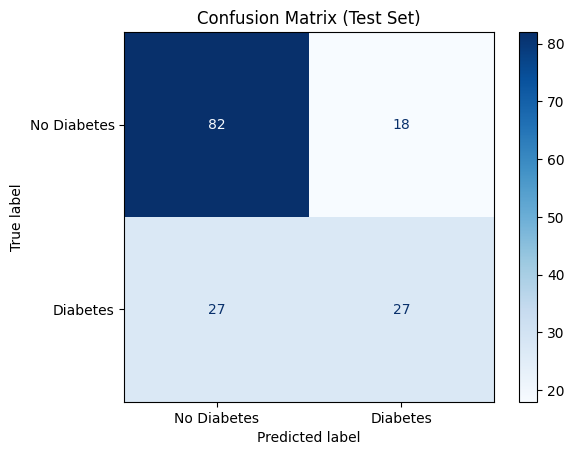

TN=82  FP=18  FN=27  TP=27


In [19]:
cm = confusion_matrix(y_test, y_test_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### Compare training and testing performance

In [20]:
comparison = pd.DataFrame({
    "Accuracy": [train_acc, test_acc],
    "Precision": [precision_score(y_train, y_train_pred), test_prec],
    "Recall": [recall_score(y_train, y_train_pred), test_rec],
    "F1-score": [f1_score(y_train, y_train_pred), test_f1],
}, index=["Train", "Test"]).round(4)
comparison

,Accuracy,Precision,Recall,F1-score
Train,0.7964,0.7697,0.5935,0.6702
Test,0.7078,0.6000,0.5000,0.5455


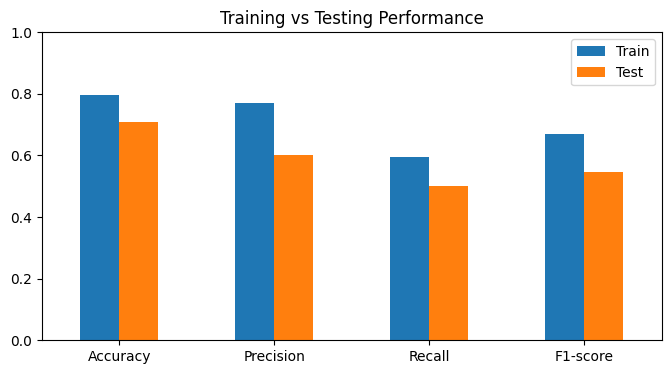

In [21]:
comparison.T.plot(kind="bar", figsize=(8, 4), ylim=(0, 1), title="Training vs Testing Performance")
plt.xticks(rotation=0)
plt.show()

**Brief interpretation:** the model reaches 79.6% accuracy on the training set and 70.8% on the test set. Precision, recall and F1 all drop by a similar amount, which points to mild overfitting on a small dataset rather than a broken model. On the test set it finds only half of the diabetic patients (recall 0.50), so it is better at ruling diabetes out than at detecting it. Part 4 analyses this in detail.

**Part 3 deliverables:** model training output (convergence, intercept, coefficients); training accuracy 79.6%; test accuracy 70.8%; precision 0.60, recall 0.50, F1 0.55; confusion matrix; training vs. testing comparison table and chart; brief interpretation above.

## Part 4 — Model Performance Analysis

In [22]:
print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy : {test_acc:.3f}")
print(f"Gap           : {abs(train_acc - test_acc):.3f}")
print(f"Baseline (always predict majority class): {1 - y_test.mean():.3f}")

Train accuracy: 0.796
Test accuracy : 0.708
Gap           : 0.089
Baseline (always predict majority class): 0.649


### Results and interpretation

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.796 | 0.708 |

Test set (154 patients): precision 0.60, recall 0.50, F1 0.55 for the diabetic class. Confusion matrix: TN = 82, FP = 18, FN = 27, TP = 27.

**Training vs. testing:** training accuracy (79.6%) is about 9 points above test accuracy (70.8%). This shows mild overfitting, which is partly expected from a single small test split of 154 samples, where a handful of patients shifts accuracy by several points. The model is simple, so the gap is not a sign of a badly overfitted model.

**Interpretation**
- The model beats the majority-class baseline (64.9%) by only about 6 points, so it learns real signal but is only modestly useful on its own.
- It is much better at identifying non-diabetic patients (recall 0.82) than diabetic ones (recall 0.50). It misses 27 of 54 diabetic patients (false negatives), because the classes are imbalanced (65/35) and the default 0.5 threshold favours the majority class.
- Accuracy alone is misleading here; precision, recall and F1 for the diabetic class give the true picture.
- `Glucose` is the most influential feature by far, followed by `BMI`, `Pregnancies`, `DiabetesPedigreeFunction` and `Age`. This agrees with medical knowledge. `Insulin`, `SkinThickness` and `BloodPressure` contribute almost nothing, partly because many of their values were missing and had to be imputed.

**Business and analytical insights**
- In screening, a false negative (a missed diabetic patient) is costlier than a false positive, so recall for the positive class matters most. Lowering the decision threshold, or using `class_weight="balanced"`, would trade some precision for higher recall.
- Elevated glucose and BMI are the strongest risk indicators and are cheap to measure, so they are good first-line screening variables.

**Limitations and next steps**
- Cross-validated accuracy on the training set (about 78.8%) is higher than the single test-split accuracy (70.8%), which confirms that one 154-patient test set gives a noisy estimate. Repeated cross-validation would give a steadier figure.
- Try tree-based models (Random Forest, Gradient Boosting) and tune hyperparameters such as the regularisation strength `C`.
- The engineered features tested in Part 1 did not help a linear model; non-linear models may make better use of them.
- Collect better data for `Insulin` and `SkinThickness`, which are missing in 49% and 30% of records respectively.

**Conclusion:** Logistic Regression gives a transparent, reasonable baseline (70.8% test accuracy), but its low recall for diabetic patients means it should be improved before it is used for screening.